# Initialization (COSMOS Legacy)

In [1]:
import pandas as pd
import numpy as np
from astropy.io import fits
import matplotlib.pyplot as plt
from astropy.coordinates import SkyCoord, match_coordinates_sky
import astropy.units as u
import matplotlib.cm as cm
import re

legacy_file = 'chandra_COSMOS_legacy_opt_NIR_counterparts_20160113_4d.fits'
hdul_l = fits.open(legacy_file)
df_l = pd.DataFrame(hdul_l[1].data)

df_l.replace(-99.000, np.nan, inplace=True)
df_l.replace(-99, np.nan, inplace=True)

# Filter for valid spectroscopic redshifts (z_spec)
mask_valid_z = (df_l['z_spec'].notna() 
                & (df_l['Qg'] >= 1.5) 
                & df_l['spec_type'].isin([1, 2])
                )
df_lz = df_l[mask_valid_z].copy()

print(f"Total sources: {len(df_l)}")
print(f"Total sources with valid z_spec: {len(df_lz)}")

# Show all columns
pd.set_option('display.max_columns', None)
df_l.head(3)

Total sources: 4016
Total sources with valid z_spec: 1681


,id_x,RA_x,DEC_x,DET_ML_F,DET_ML_S,DET_ML_H,flux_F,flux_S,flux_H,HR,HR_lo_lim,HR_up_lim,id_i,ra_i,dec_i,i_mag,i_mag_err,flag_i_mag,id_k_uv,ra_k_uv,dec_k_uv,k_uv_mag,k_uv_mag_err,id_k_cfht,ra_k_cfht,dec_k_cfht,k_cfht_mag,k_cfht_mag_err,ra_irac,dec_irac,irac_mag,irac_mag_err,ra_splash,dec_splash,splash_mag,splash_mag_err,final_id_flag,star_flag,z_best,z_spec,Instr,Qg,spec_type,z_phot,phot_type,id_xmm,dist_lum,Lx_0510,Lx_052,Lx_210,NH,abs_corr_0510,abs_corr_052,abs_corr_210,NH_lo,abs_corr_0510_lo,abs_corr_052_lo,abs_corr_210_lo,NH_up,abs_corr_0510_up,abs_corr_052_up,abs_corr_210_up
0,cid_1,149.63956,1.991034,10.910000,NaN,NaN,1.180000e-15,-3.940000e-16,-1.120000e-14,NaN,0.52,NaN,860777.0,149.639496,1.991038,26.059999,0.22,1.0,455942.0,149.639513,1.991030,22.110001,0.03,860777.0,149.639481,1.991048,22.180000,0.05,149.639435,1.991108,21.639999,0.01,149.639513,1.991030,21.420000,0.01,1.0,0,1.928,NaN,None,0.0,-9.0,1.928,3.0,NaN,15123.339844,43.229000,-42.752998,-44.206001,NaN,NaN,NaN,NaN,39.200001,0.531,0.081,0.796,NaN,NaN,NaN,NaN
1,cid_100,150.34101,2.367167,353.079987,284.350006,82.540001,1.430000e-14,3.670000e-15,9.880000e-15,-0.27,-0.39,-0.13,1210176.0,150.341034,2.367181,23.620001,0.03,1.0,704286.0,150.341070,2.367165,21.270000,0.01,1210176.0,150.341049,2.367159,21.309999,0.03,150.341049,2.367121,20.850000,0.01,150.341070,2.367165,20.590000,0.01,1.0,0,1.590,1.59,VIMOS,1.5,1.0,1.572,1.0,320.0,11920.509766,44.138000,43.547001,43.977001,0.0,1.0,1.0,1.0,0.000000,1.000,1.000,1.000,4.46,0.769,0.438,0.964
2,cid_1000,149.67574,2.010529,124.730003,141.699997,NaN,6.850000e-15,2.050000e-15,-1.320000e-14,NaN,NaN,-0.91,857679.0,149.675766,2.010352,24.190001,0.05,1.0,470092.0,149.675807,2.010416,21.240000,0.01,857679.0,149.675812,2.010447,21.540001,0.03,149.675766,2.010402,20.830000,0.01,149.675807,2.010416,20.530001,0.01,1.0,0,1.847,NaN,None,0.0,-9.0,1.847,3.0,5355.0,14344.620117,43.953999,43.430000,-44.238998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,1.000,1.000,1.000


## Labelling Spectral Types

In [2]:
def get_spec_type_label(spec_type):
    if spec_type == 0:
        return 'Star'
    elif spec_type == 1:
        return 'BL AGN'
    elif spec_type == 2:
        return 'Non-BL AGN'
    else:
        return 'Unassigned'

df_lz['spec_type_label'] = df_lz['spec_type'].apply(get_spec_type_label)

spec_colors = {
    'Star': 'orange',
    'BL AGN': 'blue',
    'Non-BL AGN': 'green',
    'Unassigned': 'gray'
}

spec_markers = {
    'Star': 'o',
    'BL AGN': 'o',
    'Non-BL AGN': 'o',
    'Unassigned': 'o'
}

spec_labels = {
    'Star': 'Star',
    'BL AGN': 'BL AGN',
    'Non-BL AGN': 'Non-BL AGN',
    'Unassigned': 'Unassigned'
}

## Histogram of Spectroscopic Redshift

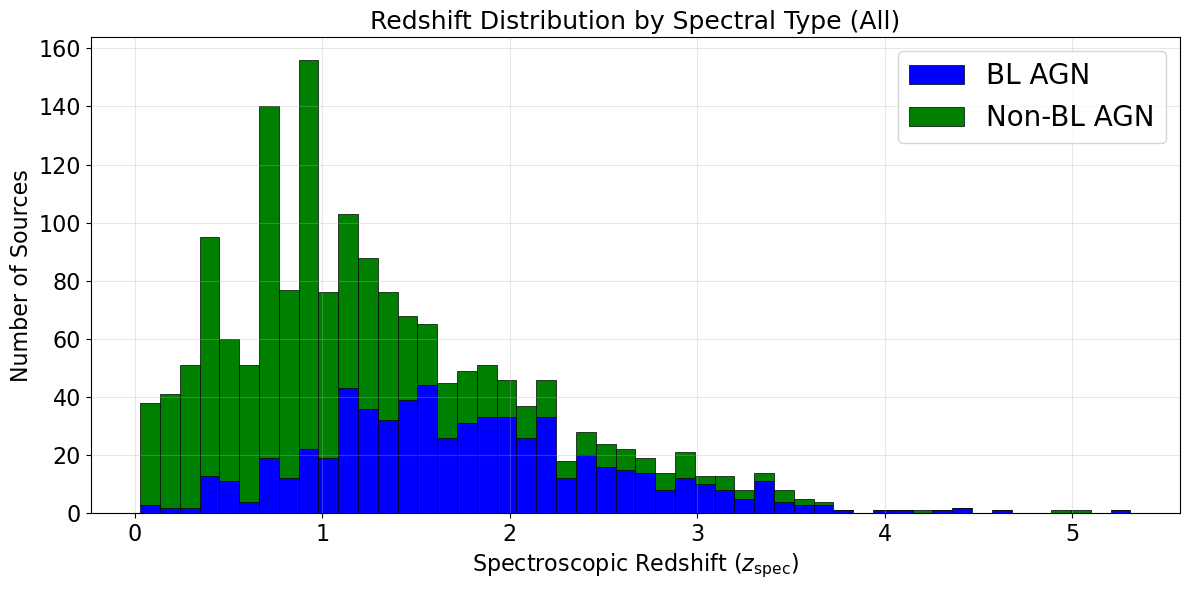

Min z_spec: 0.028999999165534973
Max z_spec: 5.309999942779541


In [3]:
# Order we want the histogram stack to appear in (bottom → top)
categories = ['BL AGN', 'Non-BL AGN']

# Collect redshift arrays per category using the label column
data_by_label = [
    df_lz.loc[df_lz['spec_type_label'] == cat, 'z_spec'].dropna()
    for cat in categories
]

# Colors and legend labels pulled from the dictionaries (kept consistent)
colors = [spec_colors[cat] for cat in categories]
legend_labels = [spec_labels[cat] for cat in categories]

plt.figure(figsize=(12, 6))

plt.hist(
    data_by_label,
    bins=50,
    stacked=True,
    color=colors,
    edgecolor='black',
    linewidth=0.5,
    label=legend_labels
)

# Formatting
plt.xlabel(r'Spectroscopic Redshift ($z_{\rm spec}$)', fontsize=16)
plt.ylabel('Number of Sources', fontsize=16)
plt.title('Redshift Distribution by Spectral Type (All)', fontsize=18)
plt.tick_params(axis='both', labelsize=16)
plt.legend(fontsize=20)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Min z_spec: {df_lz['z_spec'].min()}")
print(f"Max z_spec: {df_lz['z_spec'].max()}")

## AGN Check (2 Criterions)

In [4]:
pre_df_l = df_lz

pre_df_l['flux_S'] = pd.to_numeric(pre_df_l['flux_S'], errors='coerce')
pre_df_l['i_mag'] = pd.to_numeric(pre_df_l['i_mag'], errors='coerce')

mask_valid = (pre_df_l['flux_S'] > 0) & (pre_df_l['i_mag'] > 0)
pre_df_l = pre_df_l[mask_valid].copy()

print(f"Sources with valid flux_S and i_mag: {len(pre_df_l)}")

pre_df_l['X_over_O'] = np.log10(pre_df_l['flux_S']) + (pre_df_l['i_mag'] / 2.5) + 5.352

# Two AGN criteria
# Criterion 1: L_0.5-10 keV > 3e42 erg/s (log10 > 42.5)
mask_luminosity = pre_df_l['Lx_0510'] > 42.5   # Where 42.5 = np.log10(3) + 42

# Criterion 2: -1 <= X/O <= 1
mask_xo = (pre_df_l['X_over_O'] >= -1.0) & (pre_df_l['X_over_O'] <= 1.0)

# Combine with OR
agn_mask = mask_luminosity | mask_xo

crit = pre_df_l[agn_mask].copy()

print(f"Sources passing at least one criterion: {len(crit)}")
print(f"Sources rejected: {len(pre_df_l) - len(crit)}")

Sources with valid flux_S and i_mag: 1395
Sources passing at least one criterion: 1259
Sources rejected: 136


### Making sure everything is correct

In [5]:
pd.set_option('display.max_columns', None)
crit[['id_x', 'spec_type_label', 'z_spec', 'Lx_0510', 'X_over_O']].head(10)

,id_x,spec_type_label,z_spec,Lx_0510,X_over_O
1,cid_100,BL AGN,1.590,44.138000,0.364666
4,cid_1002,Non-BL AGN,1.623,43.429001,-0.279997
10,cid_1008,BL AGN,1.681,43.678001,-0.417854
13,cid_1010,Non-BL AGN,0.937,43.500999,0.018452
15,cid_1013,Non-BL AGN,1.231,44.009998,0.508458
17,cid_1015,Non-BL AGN,1.377,43.412998,0.107852
19,cid_1017,Non-BL AGN,1.329,43.202999,-1.232225
20,cid_1018,BL AGN,2.421,43.860001,-0.192398
22,cid_102,BL AGN,1.847,44.021000,-0.788662
24,cid_1021,Non-BL AGN,2.162,43.848000,-0.318628


## Plot of Luminosity vs Spectroscopic Redshifts

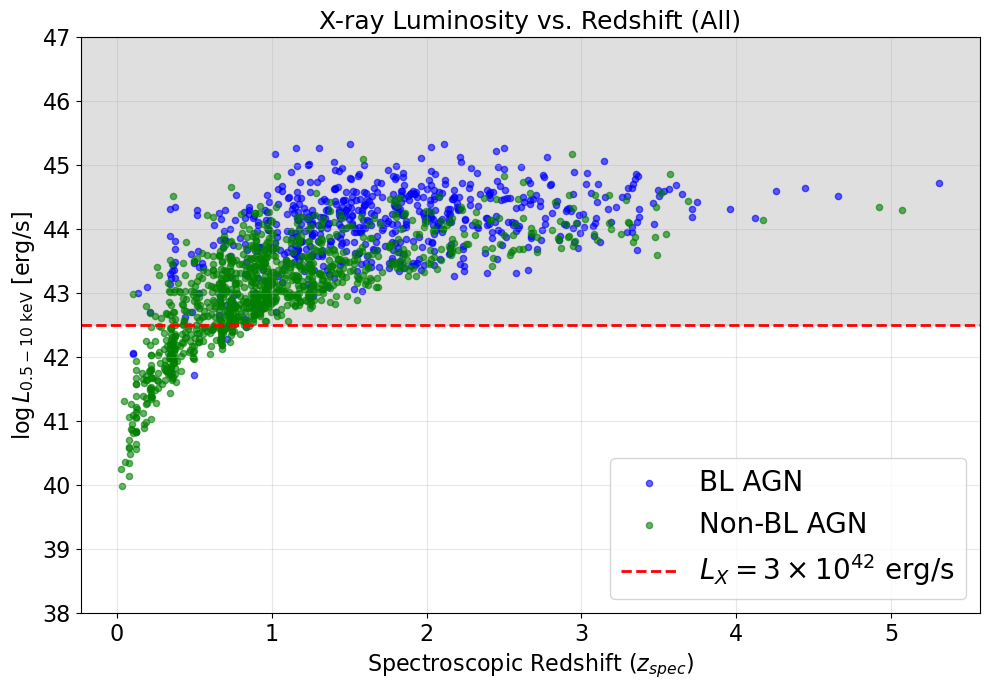

In [6]:
fig, ax = plt.subplots(figsize=(10, 7))

# Filter out extreme Lx values for plotting
plot_df = crit[crit['Lx_0510'] > 0].copy()

for stype in ['BL AGN', 'Non-BL AGN']:
    subset = df_lz[df_lz['spec_type_label'] == stype]
    ax.scatter(
        subset['z_spec'],
        subset['Lx_0510'],
        s=20,
        alpha=0.6,
        color=spec_colors[stype],
        marker=spec_markers[stype],
        label=spec_labels[stype]
    )

# Add the luminosity threshold line
ax.axhline(y=42.5, color='red', linestyle='--', linewidth=2, label=r'$L_X = 3 \times 10^{42}$ erg/s')
ax.axhspan(42.5, 47, color='gray', alpha=0.25, zorder=0)

# Labels and formatting
ax.set_xlabel('Spectroscopic Redshift ($z_{spec}$)', fontsize=16)
ax.set_ylabel(r'$\log L_{0.5-10\ \mathrm{keV}}$ [erg/s]', fontsize=16)
ax.set_title('X-ray Luminosity vs. Redshift (All)', fontsize=18)
ax.legend(loc='lower right', fontsize=20)
ax.grid(True, alpha=0.3)
ax.set_ylim(38, 47)

plt.tick_params(axis='both', labelsize=16)
plt.tight_layout()
plt.show()

## Plot of X/O Ratio vs Spectroscopic Redshifts

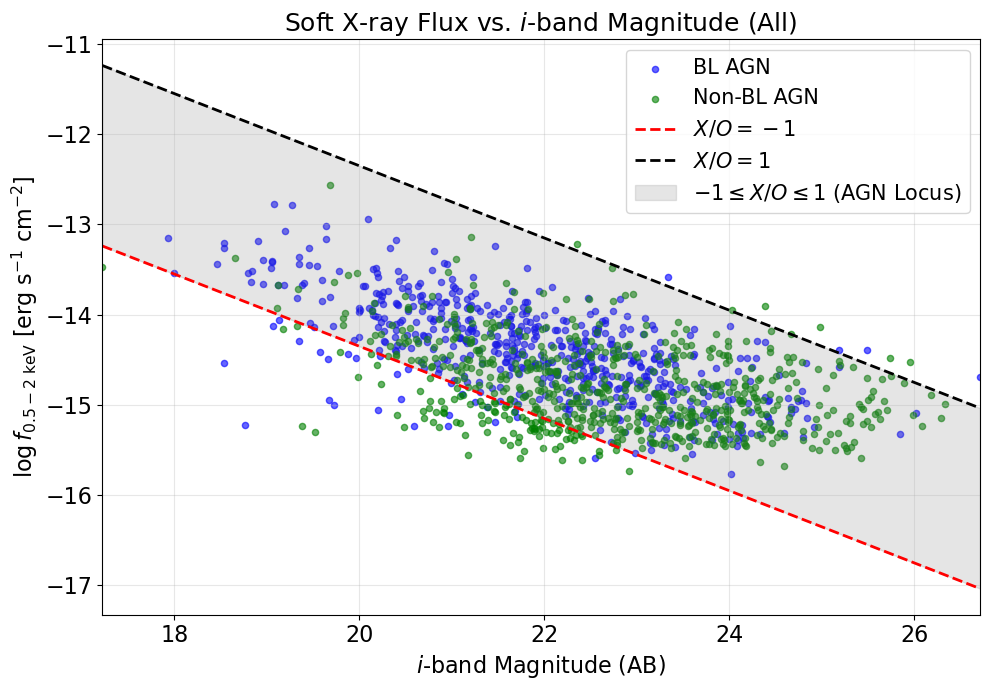

In [7]:
fig2, ax2 = plt.subplots(figsize=(10, 7))

# Filter out invalid magnitudes and fluxes
plot_df2 = crit.copy()

for stype in ['BL AGN', 'Non-BL AGN']:
    subset = plot_df2[plot_df2['spec_type_label'] == stype]
    ax2.scatter(
        subset['i_mag'],
        np.log10(subset['flux_S']),
        s=20,
        alpha=0.6,
        color=spec_colors[stype],
        marker=spec_markers[stype],
        label=spec_labels[stype]
    )

# --- Add the AGN locus lines ---
# X/O = -1 and X/O = 1 lines
i_mag_range = np.linspace(plot_df2['i_mag'].min(), plot_df2['i_mag'].max(), 100)

# X/O = -1: log10(flux_S) = -1 - i_mag/2.5 - 5.352
log_fx_minus1 = -1 - i_mag_range / 2.5 - 5.352
ax2.plot(i_mag_range, log_fx_minus1, color='red', linestyle='--', linewidth=2, label=r'$X/O = -1$')

# X/O = 1: log10(flux_S) = 1 - i_mag/2.5 - 5.352
log_fx_plus1 = 1 - i_mag_range / 2.5 - 5.352
ax2.plot(i_mag_range, log_fx_plus1, color='black', linestyle='--', linewidth=2, label=r'$X/O = 1$')

# Shade the AGN locus region (-1 <= X/O <= 1)
ax2.fill_between(
    i_mag_range,
    log_fx_minus1,
    log_fx_plus1,
    color='gray',
    alpha=0.2,
    label=r'$-1 \leq X/O \leq 1$ (AGN Locus)'
)

# --- Labels and formatting ---
ax2.set_xlabel('$i$-band Magnitude (AB)', fontsize=16)
ax2.set_ylabel(r'$\log f_{0.5-2\ \mathrm{keV}}$ [erg s$^{-1}$ cm$^{-2}$]', fontsize=16)
ax2.set_title('Soft X-ray Flux vs. $i$-band Magnitude (All)', fontsize=18)
ax2.legend(loc='upper right', fontsize=15)
ax2.grid(True, alpha=0.3)

# Set x-axis limits (bright to faint)
ax2.set_xlim(plot_df2['i_mag'].min(), plot_df2['i_mag'].max())

plt.tick_params(axis='both', labelsize=16)
plt.tight_layout()
plt.show()